<a href="https://colab.research.google.com/github/Ethan-Tse/econ3916-midterm/blob/main/Model_Draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [10]:
SOURCE_URL = "https://educationdata.urban.org/"       # the page or file you downloaded from
DOWNLOAD_DATE = "2026-11-05"    # YYYY-MM-DD
FILE_NAME = "GraduationRates.csv, Expenditures_Finances.csv, Finance_2015_2017.csv"       # the file as saved in your repository's data/ folder

**Who collected it, for what purpose, what is missing and why?**

The data was collected by the Urban Institue for the Education Data Portal, aggregating administrative records from the Common Core of Data maintained by the National Center for Education Statistics and performance files from the US Department of Education. The purpose is to track public school district finance, enrollment, and student academic statistics across states. Missing values are concentrated in graduation rates due to FERPA federal privacy suppression rules for small cohorts or specific student subgroups, which represents a MNAR.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [11]:
import os

GRAD_FILE = "GraduationRates.csv"
FIN_FILE_2018 = "Expenditures&Finances.csv"        # 2018-2020 finance
FIN_FILE_EARLY = "Finance_2015_2017.csv"           # 2015-2017 finance
COHORT_YEAR = 2018
SPEND_YEARS = [2015, 2016, 2017, 2018]             # the four years the 2018 cohort was in high school
target_agency = "Regular local school district"
EXCLUDE_COE = True       # drop County Offices of Education (special-purpose agencies; see Section 1)

FIN_COLS = ["year", "leaid", "lea_name", "state_location", "city_location",
            "agency_type", "enrollment", "exp_current_instruction_total"]

def read_fin(path):
    """Read a finance CSV and check it has the expected columns."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found. Files here: {sorted(os.listdir('.'))}")
    try:
        d = pd.read_csv(path, encoding="utf-8-sig")
    except Exception as err:
        with open(path, encoding="utf-8-sig", errors="replace") as f:
            first_lines = [f.readline()[:150] for _ in range(3)]
        raise ValueError(f"Could not parse {path} ({os.path.getsize(path):,} bytes). "
                         f"First lines: {first_lines}") from err
    missing = [c for c in FIN_COLS if c not in d.columns]
    if missing:
        raise ValueError(f"{path} is missing columns {missing}. It has: {list(d.columns)}")
    return d[FIN_COLS]

df_grads = pd.read_csv(GRAD_FILE, encoding="utf-8-sig")
fin = pd.concat([read_fin(FIN_FILE_EARLY), read_fin(FIN_FILE_2018)], ignore_index=True)
fin = fin[fin["year"].isin(SPEND_YEARS)].drop_duplicates(["leaid", "year"])

# Text such as "Not applicable" or "Missing/not reported" becomes NaN; zero enrollment is not a real value
fin["exp_current_instruction_total"] = pd.to_numeric(fin["exp_current_instruction_total"], errors="coerce")
fin["enrollment"] = pd.to_numeric(fin["enrollment"], errors="coerce").replace(0, np.nan)
df_grads["grad_rate_midpt"] = pd.to_numeric(df_grads["grad_rate_midpt"], errors="coerce")
df_grads["enrollment"] = pd.to_numeric(df_grads["enrollment"], errors="coerce").replace(0, np.nan)

# Traditional public school systems only
df_grads = df_grads[(df_grads["agency_type"] == target_agency) & (df_grads["year"] == COHORT_YEAR)].copy()
fin = fin[fin["agency_type"] == target_agency].copy()
if EXCLUDE_COE:
    df_grads = df_grads[~df_grads["lea_name"].str.contains("County Office of Education", case=False)]
    fin = fin[~fin["lea_name"].str.contains("County Office of Education", case=False)]

# Annual per-pupil instructional spending, then the average over all four years (all four required)
fin["spending_per_pupil"] = fin["exp_current_instruction_total"] / fin["enrollment"]
wide = fin.pivot(index="leaid", columns="year", values="spending_per_pupil").reindex(columns=SPEND_YEARS)
spend = pd.DataFrame({
    "spending_per_pupil": wide[COHORT_YEAR],                                   # 2018 only
    "spending_4yr_avg": wide.mean(axis=1).where(wide.notna().all(axis=1)),     # NaN unless all four years exist
}).reset_index()

# One row per district: the 2018 graduation rate and that district's 4-year spending
df = df_grads.merge(spend, on="leaid", how="left", validate="one_to_one")

# Sample-flow counts for the report
n_regular = len(df)
n_with_grad = int(df["grad_rate_midpt"].notna().sum())
n_with_spend = int((df["grad_rate_midpt"].notna() & df["spending_4yr_avg"].notna()).sum())
est = df.dropna(subset=["grad_rate_midpt", "spending_4yr_avg", "enrollment"]).copy()

# Table 1: Summary Statistics (estimation sample, so every row has the same N)
summary_vars = {
    "grad_rate_midpt": "High School Graduation Rate, 2018 cohort (%)",
    "spending_4yr_avg": "4-Year Avg Instructional Spending per Pupil, 2015-2018 ($)",
    "spending_per_pupil": "2018 Instructional Spending per Pupil ($)",
    "enrollment": "District Total Enrollment, 2018",
}
summary_table = est[list(summary_vars.keys())].rename(columns=summary_vars).describe().T
summary_table = summary_table[["count", "mean", "std", "min", "50%", "max"]]
summary_table.columns = ["N", "Mean", "Std Dev", "Min", "Median", "Max"]
summary_table["N"] = summary_table["N"].astype(int)

print(f"Regular districts in {COHORT_YEAR}: {n_regular:,}   with a graduation rate: {n_with_grad:,}   "
      f"also with 4-year spending: {n_with_spend:,}   estimation sample: {len(est):,}")
print("\nTable 1: Summary Statistics for California and Texas School Districts (estimation sample)")
display(summary_table.round(2))

Regular districts in 2018: 1,958   with a graduation rate: 1,371   also with 4-year spending: 1,366   estimation sample: 1,366

Table 1: Summary Statistics for California and Texas School Districts (estimation sample)


,N,Mean,Std Dev,Min,Median,Max
"High School Graduation Rate, 2018 cohort (%)",1366,90.71,7.51,5.00,92.00,99.00
"4-Year Avg Instructional Spending per Pupil, 2015-2018 ($)",1366,6610.90,1555.34,2989.99,6343.50,31654.14
2018 Instructional Spending per Pupil ($),1366,7063.91,2216.20,4619.15,6673.08,61840.43
"District Total Enrollment, 2018",1366,6999.75,19191.31,61.00,1675.00,495255.00


In [12]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "district-year"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "grad_rate_midpt"     # your dependent variable's column name
MAIN_X = "spending_4yr_avg"      # your main explanatory variable's column name
CONTROLS = ["enrollment", "state_location", "year"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 1,958   Columns: 11   One row is: district-year

Missing values per column:
grad_rate_midpt     587
spending_4yr_avg     11
enrollment            7
state_location        0
year                  0

Skew of grad_rate_midpt: -3.51 (above about 1, consider a log)


**Answer before you go on.**

**1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.**
No. The state is fixed and a district’s spending cannot move it from California to Texas. District enrollment is largely predetermined, since a district’s size in 2018 reflects its population and history more than its spending over the previous four years, so I treat it as a confounder rather than a mediator. The one risk is that spending could slowly draw families into a district and raise enrollment, so I will check how much the coefficient on spending changes with and without enrollment and report what each version measures.

**2. Are all your variables in the same units and for the same years?**
Yes. Every variable describes the 2018 graduating cohort, with spending averaged over 2015 to 2018, the four years that cohort was in grades 9 to 12. One row is one district. Graduation rates are percentages and spending is instructional dollars per pupil. Spending is in nominal dollars, not adjusted for inflation across 2015 to 2018

**3. If your question is about a policy, where is the period before it?**
It is not a policy question. The question concerns continuous variation in spending across districts, not a before-and-after change, so there is no policy date and no pre-period. I use one cross-section and do not estimate a difference-in-differences.

**Question:** How is cumulative four-year per-pupil instructional spending associated with the 2018 cohort graduation rate across regular school districts in California and Texas?

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

In [13]:
# The estimation sample from Section 1: districts with a graduation rate, 4-year spending and enrollment
sample = est.copy()
sample["log_spending"] = np.log(sample["spending_4yr_avg"])
print("Districts in the sample:", len(sample))
print(sample["state_location"].value_counts().to_string())
sample = est.copy()
sample["log_spending"] = np.log(sample["spending_4yr_avg"])

Districts in the sample: 1366
state_location
TX    963
CA    403


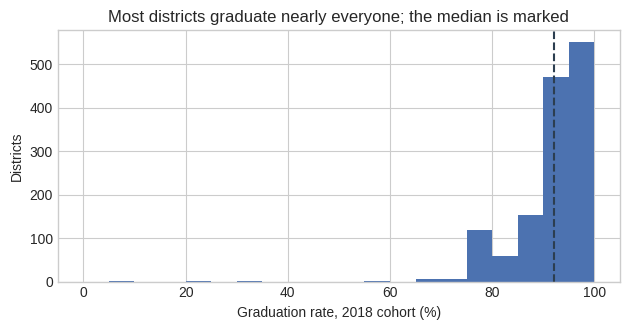

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(sample["grad_rate_midpt"], bins=range(0, 105, 5), color="#4C72B0")
ax.axvline(sample["grad_rate_midpt"].median(), color="#2c3e50", ls="--", lw=1.5)
ax.set(xlabel="Graduation rate, 2018 cohort (%)", ylabel="Districts",
       title="Most districts graduate nearly everyone; the median is marked")
plt.tight_layout(); plt.show()

*Figure 1. Most districts graduate nearly everyone: the median district has a 92% graduation rate, and 74.7% are at or above 90%. The thin tail of low-graduation districts gives a skew of -3.18, because the rate cannot exceed 100.*

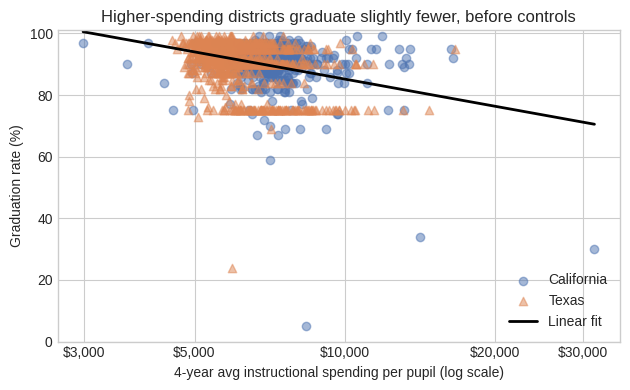

In [15]:
fig, ax = plt.subplots(figsize=(6.4, 4))
ca = sample["state_location"] == "CA"
ax.scatter(sample.loc[ca, "spending_4yr_avg"], sample.loc[ca, "grad_rate_midpt"], color="#4C72B0", alpha=0.5, label="California")
ax.scatter(sample.loc[~ca, "spending_4yr_avg"], sample.loc[~ca, "grad_rate_midpt"], color="#DD8452", marker="^", alpha=0.5, label="Texas")
slope, intercept = np.polyfit(sample["log_spending"], sample["grad_rate_midpt"], 1)
xs = np.linspace(sample["log_spending"].min(), sample["log_spending"].max(), 100)
ax.plot(np.exp(xs), intercept + slope * xs, color="black", lw=2, label="Linear fit")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([3000, 5000, 10000, 20000, 30000])
ax.set_xticklabels(["$3,000", "$5,000", "$10,000", "$20,000", "$30,000"])
ax.set(xlabel="4-year avg instructional spending per pupil (log scale)", ylabel="Graduation rate (%)", ylim=(0, 101),
       title="Higher-spending districts graduate slightly fewer, before controls")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

*Figure 2. Before any controls, districts that spend more per pupil have slightly lower graduation rates, not higher (correlation -0.32; about 1.21 points lower for every 10% more spending). That is the opposite of what a spending-helps story predicts, which suggests the raw pattern reflects which kinds of districts spend more, such as state and size, rather than what spending does. The line is a raw fit with no controls. The vertical axis runs the full 0 to 100 and the horizontal axis is logarithmic, so equal distances are equal percentage changes in spending. The flat band at 75% is 105 districts (99 in Texas) reported at the midpoint of a range, not a real cluster.*

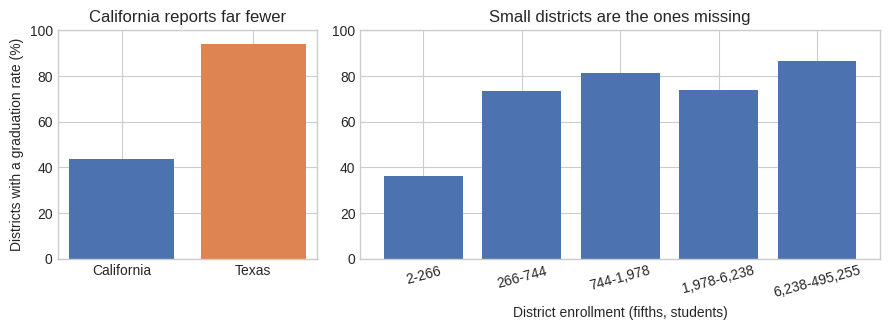

In [16]:
base = df.copy()                                    # all 2018 regular districts, with or without a graduation rate
base["has_rate"] = base["grad_rate_midpt"].notna()
base["size_group"] = pd.qcut(base["enrollment"], 5, duplicates="drop")
by_state = base.groupby("state_location")["has_rate"].mean() * 100
by_size = base.groupby("size_group", observed=True)["has_rate"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(["California", "Texas"], [by_state["CA"], by_state["TX"]], color=["#4C72B0", "#DD8452"])
ax[0].set(ylabel="Districts with a graduation rate (%)", ylim=(0, 100), title="California reports far fewer")
ax[1].bar([f"{int(i.left):,}-{int(i.right):,}" for i in by_size.index], by_size.values, color="#4C72B0")
ax[1].set(xlabel="District enrollment (fifths, students)", ylim=(0, 100), title="Small districts are the ones missing")
ax[1].tick_params(axis="x", labelrotation=15)
plt.tight_layout(); plt.show()

*Figure 3. Graduation rates are far more often reported in Texas (94% of districts) than in California (44%), and for large districts than small ones: 36% of districts in the smallest enrollment fifth have one, against 87% in the largest. Of the 525 California districts without a rate, 437 have 'Elementary' in their name, which suggests they run no high school and so have no graduates to report. The sample therefore leans toward Texas and toward larger districts.*

In [17]:
table2 = sample.groupby("state_location").agg(districts=("leaid", "count"), grad_rate=("grad_rate_midpt", "mean"),
                                              spending=("spending_4yr_avg", "mean"), enrollment=("enrollment", "median"))
table2.index = ["California", "Texas"]
table2.columns = ["Districts", "Mean graduation rate (%)", "Mean 4-yr avg spending ($)", "Median enrollment"]
table2.round(1)

,Districts,Mean graduation rate (%),Mean 4-yr avg spending ($),Median enrollment
California,403,89.5,7492.4,4770.0
Texas,963,91.2,6242.0,1098.0


*Table 2. California districts in the sample spend more per pupil than Texas ones yet graduate slightly fewer students (89.5% against 91.2%), and district sizes differ widely (median enrollment 4,770 against 1,098). State differences alone could produce the negative raw association in Figure 2, which is why state enters the model as a control.*

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [18]:
sample["texas"] = (sample["state_location"] == "TX").astype(int)
sample["log_enrollment"] = np.log(sample["enrollment"])

m1 = smf.ols("grad_rate_midpt ~ log_spending", sample).fit(cov_type="HC1")
m2 = smf.ols("grad_rate_midpt ~ log_spending + texas", sample).fit(cov_type="HC1")
m3 = smf.ols("grad_rate_midpt ~ log_spending + texas + log_enrollment", sample).fit(cov_type="HC1")

def regtable(models, names):
    labels = {"log_spending": "Log 4-year avg spending per pupil", "texas": "Texas (California = 0)",
              "log_enrollment": "Log district enrollment", "Intercept": "Constant"}
    index = [r for label in labels.values() for r in (label, label + " (se)")] + ["N", "R²"]
    rows = {}
    for name, m in zip(names, models):
        col = {}
        for v, label in labels.items():
            if v in m.params:
                col[label] = f"{m.params[v]:.2f}"
                col[label + " (se)"] = f"({m.bse[v]:.2f})"
        col["N"], col["R²"] = f"{int(m.nobs):,}", f"{m.rsquared:.2f}"
        rows[name] = col
    return pd.DataFrame(rows).reindex(index).fillna("")

regtable([m1, m2, m3], ["(1) Spending only", "(2) Adds state", "(3) Main: adds size"])

,(1) Spending only,(2) Adds state,(3) Main: adds size
Log 4-year avg spending per pupil,-12.72,-13.23,-9.55
Log 4-year avg spending per pupil (se),(1.90),(2.07),(2.30)
Texas (California = 0),,-0.52,1.25
Texas (California = 0) (se),,(0.50),(0.63)
Log district enrollment,,,0.94
Log district enrollment (se),,,(0.18)
Constant,202.35,207.21,166.54
Constant (se),(16.59),(18.31),(21.03)
N,"1,366","1,366","1,366"
R²,0.10,0.11,0.13


*Table 3. Regression of the 2018 cohort graduation rate (percentage points) on log 4-year average instructional spending per pupil, for 1,366 California and Texas districts. Standard errors in parentheses are heteroskedasticity-robust (HC1). Column 3 is the main model. The constant is the predicted rate at a log spending of zero, far outside the data, so it is not interpreted.*

In [19]:
k = np.log(1.10)
pfmt = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
b, (lo, hi) = m3.params["log_spending"], m3.conf_int().loc["log_spending"]
print(f"Main model: coefficient on log spending {b:.2f} (SE {m3.bse['log_spending']:.2f}, 95% CI {lo:.2f} to {hi:.2f}), {pfmt(m3.pvalues['log_spending'])}")
print(f"10% more spending -> {b * k:+.2f} points (95% CI {lo * k:+.2f} to {hi * k:+.2f})")
med = sample["spending_4yr_avg"].median()
print(f"At the median spending of ${med:,.0f} per pupil, 10% more is ${0.10 * med:,.0f}")
sd = sample["log_spending"].std()
print(f"One SD of log spending ({sd:.2f}, about {100 * (np.exp(sd) - 1):.0f}% more spending) -> {b * sd:+.2f} points, "
      f"{b * sd / sample['grad_rate_midpt'].std():+.2f} SD of the graduation rate")
print(f"Spending coefficient: {m1.params['log_spending']:.2f} with no controls, {m2.params['log_spending']:.2f} adding state, "
      f"{m3.params['log_spending']:.2f} adding size")

be, (elo, ehi) = m3.params["log_enrollment"], m3.conf_int().loc["log_enrollment"]
print(f"Enrollment: coefficient {be:.2f} (SE {m3.bse['log_enrollment']:.2f}), {pfmt(m3.pvalues['log_enrollment'])}; "
      f"a district twice as large -> {be * np.log(2):+.2f} points (95% CI {elo * np.log(2):+.2f} to {ehi * np.log(2):+.2f})")
bt, (tlo, thi) = m3.params["texas"], m3.conf_int().loc["texas"]
print(f"Texas vs California: {bt:+.2f} points (95% CI {tlo:+.2f} to {thi:+.2f}), {pfmt(m3.pvalues['texas'])}")
print(f"corr(log enrollment, log spending) = {sample['log_enrollment'].corr(sample['log_spending']):.2f};  "
      f"corr(log enrollment, graduation rate) = {sample['log_enrollment'].corr(sample['grad_rate_midpt']):.2f}")
print(f"N = {int(m3.nobs):,}, R² = {m3.rsquared:.3f} (spending only: {m1.rsquared:.3f})")

Main model: coefficient on log spending -9.55 (SE 2.30, 95% CI -14.05 to -5.05), p < 0.001
10% more spending -> -0.91 points (95% CI -1.34 to -0.48)
At the median spending of $6,344 per pupil, 10% more is $634
One SD of log spending (0.19, about 21% more spending) -> -1.82 points, -0.24 SD of the graduation rate
Spending coefficient: -12.72 with no controls, -13.23 adding state, -9.55 adding size
Enrollment: coefficient 0.94 (SE 0.18), p < 0.001; a district twice as large -> +0.65 points (95% CI +0.41 to +0.89)
Texas vs California: +1.25 points (95% CI +0.02 to +2.49), p = 0.046
corr(log enrollment, log spending) = -0.25;  corr(log enrollment, graduation rate) = 0.23
N = 1,366, R² = 0.133 (spending only: 0.105)


**Roles of the controls.** *State* (Texas = 1) blocks a confounding path. California and Texas differ in how schools are funded, in graduation requirements and in how graduation rates are reported (Table 2 and Figure 3), all of which touch both spending and graduation. Adding it barely moves the spending coefficient (-12.72 to -13.23), so it matters little for the estimate and earns its place on design grounds. It would be a bad control only if spending decided which state a district is in, and it cannot, so it is neither a mediator nor a collider. *Log enrollment* also blocks a confounding path: size affects spending per pupil (the correlation is -0.25, because small districts spread fixed costs over fewer students) and affects graduation (the correlation is 0.23). It does most of the work here: adding it moves the spending coefficient from -13.23 to -9.55. It would be a bad control if spending drew families into a district, because enrollment would then sit on the path from spending to graduation (a mediator) and holding it fixed would remove part of the effect I want; it would also be a bad control if enrollment responded to both spending and unmeasured school quality (a collider). Enrollment here is the 2018 count, measured after most of the spending, so I treat it as set mostly by the local population. Columns 2 and 3 show the estimate without and with it, and both are clearly negative. *Left out:* district poverty and student need. They are the obvious confounder, since higher-need districts tend to receive more funding and to graduate fewer students, which would produce a negative coefficient even if spending did nothing. The data here do not contain it, which is the main reason the -9.55 is not read as the effect of spending. There is no year control because the sample is one graduating cohort, so year does not vary.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

*Your words here.*

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [22]:
REPORT_NUMBERS = {
    # "Section 1: rows in the final sample": ...,
    # "Section 3: coefficient on <your main predictor>": ...,
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.